# Day 25 — Sales EDA
Project 1: Retail Sales & Customer Performance Analysis

Objective: What is happening with the company’s sales?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Image
sns.set_theme(style="whitegrid")
Path("charts").mkdir(exist_ok=True)
Path("summaries").mkdir(exist_ok=True)
df = pd.read_csv("transformed_retail_sales.csv", parse_dates=["Order_Date"])
assert df.Sales.notna().all()
assert (df.Sales == df.Order_Value).all()
display(df.head())
print(df.shape)

,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Customer_Rating_Was_Imputed,Year,Month,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Total_Spending,Customer_Segment,Sales_Category,Customer_Order_Count,Customer_Type,Product_Total_Sales,Product_Performance,Order_Size,Day_Name,Is_Weekend
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,False,2026,10,October,4,NaN,1300,13350,Medium Value,Medium,5,Repeat,14950,Low,Small,Friday,False
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,False,2026,10,October,4,NaN,960,10700,Medium Value,Low,5,Repeat,6720,Low,Medium,Saturday,True
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,False,2026,10,October,4,NaN,4400,13350,Medium Value,High,5,Repeat,24200,High,Medium,Sunday,True
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,False,2026,10,October,4,NaN,7500,17780,High Value,High,5,Repeat,36000,High,Large,Monday,False
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,False,2026,10,October,4,NaN,650,12450,Medium Value,Low,5,Repeat,14950,Low,Small,Tuesday,False


(30, 27)


## Task 1 — Total sales

In [2]:
total = df["Sales"].sum()
print(f"Total sales: INR {total:,.2f}")
print("Orders:", df.Order_ID.nunique())
print("Average order value:", total / df.Order_ID.nunique())
display(df.Sales.describe())
df.Sales.describe().to_csv("summaries/sales_statistics.csv")

Total sales: INR 81,870.00
Orders: 30
Average order value: 2729.0


count      30.000000
mean     2729.000000
std      2136.342911
min       320.000000
25%       995.000000
50%      2075.000000
75%      4125.000000
max      7500.000000
Name: Sales, dtype: float64

## Tasks 2–5 — Monthly, category, geographic and product sales

In [3]:
monthly = df.groupby("Month_Name")["Sales"].sum().reindex(df.sort_values("Order_Date").Month_Name.unique())
category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
city = df.groupby("City")["Sales"].sum().sort_values(ascending=False)
product = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)
top = product.head(10)
bottom = product.sort_values().head(10)
pivot = pd.pivot_table(df, index="Category", columns="City", values="Sales", aggfunc="sum", fill_value=0)
for name, table in {"monthly":monthly,"category":category,"city":city,"product":product,"top_products":top,"bottom_products":bottom,"category_city_pivot":pivot}.items():
    print(name); display(table); table.to_csv(f"summaries/{name}.csv")
for table in [monthly, category, city, product]:
    assert table.sum() == total
assert pivot.to_numpy().sum() == total

monthly


Month_Name
October    81870
Name: Sales, dtype: int64

category


Category
Electronics    36000
Home           24200
Clothing       14950
Grocery         6720
Name: Sales, dtype: int64

city


City
Pune      33140
Nashik    24680
Nagpur    14970
Mumbai     9080
Name: Sales, dtype: int64

... (4 outputs left out)

bottom_products


Product
Rice           6720
T-Shirt       14950
Lamp          24200
Headphones    36000
Name: Sales, dtype: int64

category_city_pivot


City,Mumbai,Nagpur,Nashik,Pune
Category,,,,
Clothing,2600,1950,2600,7800
Electronics,3000,4500,12000,16500
Grocery,1280,1920,1280,2240
Home,2200,6600,8800,6600


City is the available geographic field; it is not a Region hierarchy. Top and bottom lists contain up to ten available products and can overlap when fewer than twenty products exist. Only October 2026 is observed; month-over-month growth cannot be inferred.

## Task 6 — Profit analysis
Total profit, profit by category, region and product are unavailable: no Profit or Cost field exists and Profit_Margin is blank. No zero or estimated profit is substituted.

In [4]:
print("Profit column available:", "Profit" in df.columns)
print("Non-null profit margins:", df.Profit_Margin.notna().sum())
profit_status = pd.DataFrame({"Metric":["Total profit","Profit by category","Profit by region","Profit by product"],"Status":["Unavailable — no profit/cost data"]*4})
display(profit_status)
profit_status.to_csv("summaries/profit_availability.csv", index=False)

Profit column available: False
Non-null profit margins: 0


,Metric,Status
0,Total profit,Unavailable — no profit/cost data
1,Profit by category,Unavailable — no profit/cost data
2,Profit by region,Unavailable — no profit/cost data
3,Profit by product,Unavailable — no profit/cost data


## Task 7 — Visualizations and interpretations

In [5]:
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(f"charts/{name}.png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=f"charts/{name}.png"))

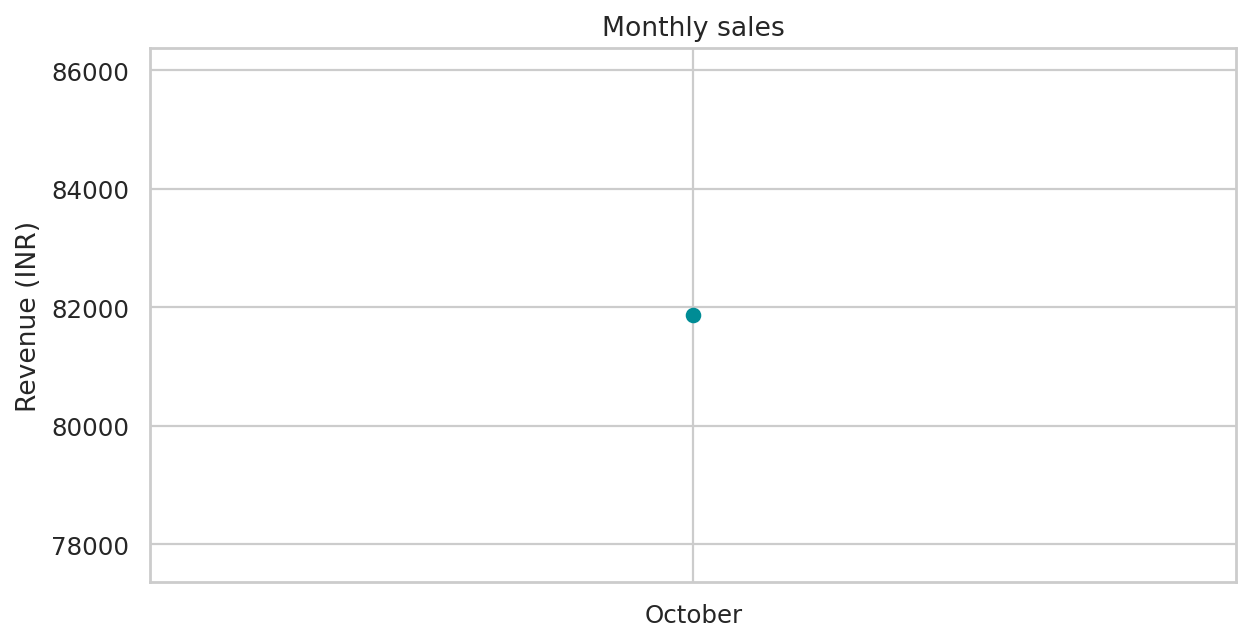

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(monthly.index, monthly.values, marker="o", color="#008C95"); ax.set_ylabel("Revenue (INR)")
ax.set_title('Monthly sales')
finish(fig, '01_monthly')

**What does this chart tell us?** October 2026 contributes INR 81,870. A single point is not evidence of a trend.

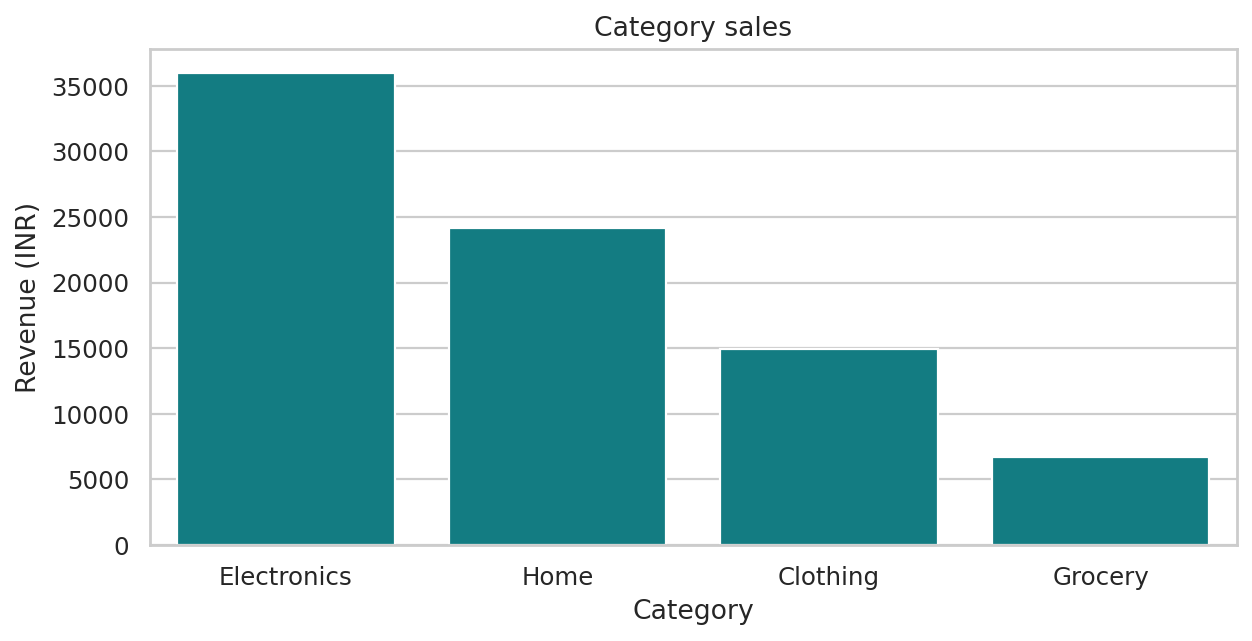

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=category.index, y=category.values, ax=ax, color="#008C95"); ax.set_ylabel("Revenue (INR)")
ax.set_title('Category sales')
finish(fig, '02_category')

**What does this chart tell us?** Electronics leads with INR 36,000 (44.0% of revenue); Grocery is lowest at INR 6,720.

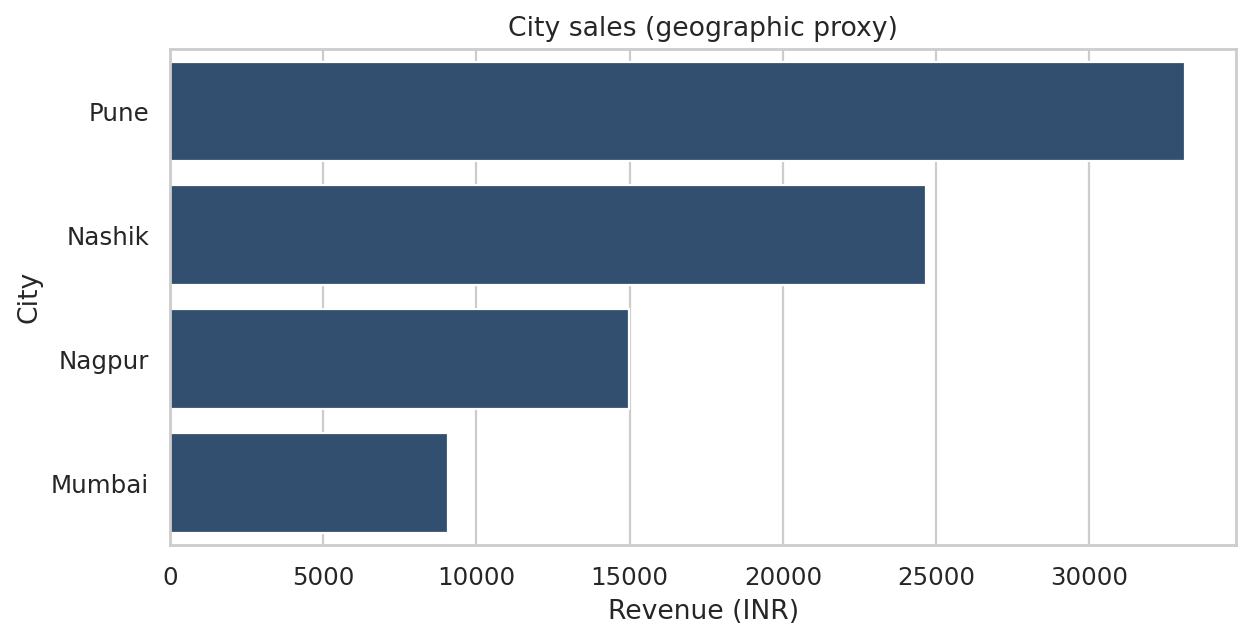

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(y=city.index, x=city.values, ax=ax, color="#294E79"); ax.set_xlabel("Revenue (INR)")
ax.set_title('City sales (geographic proxy)')
finish(fig, '03_city')

**What does this chart tell us?** Pune leads with INR 33,140; Mumbai records INR 9,080. City is not a formal region.

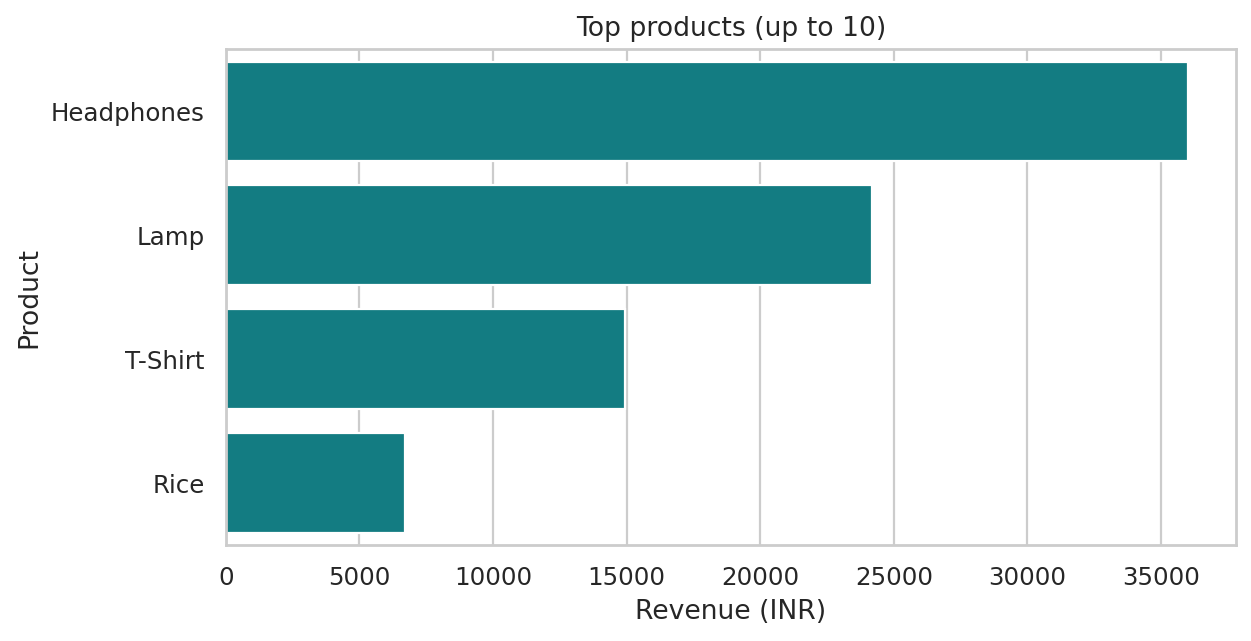

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(y=top.index, x=top.values, ax=ax, color="#008C95"); ax.set_xlabel("Revenue (INR)")
ax.set_title('Top products (up to 10)')
finish(fig, '04_top_products')

**What does this chart tell us?** Headphones leads with INR 36,000. There are 4 distinct products; the top list includes up to ten.

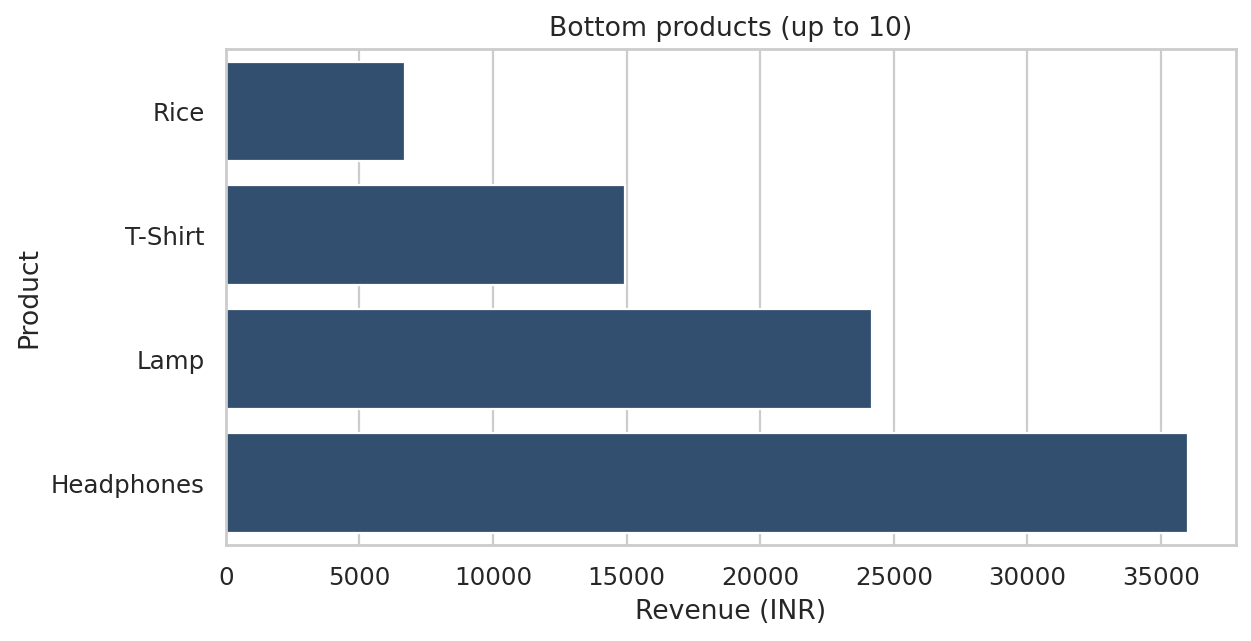

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(y=bottom.index, x=bottom.values, ax=ax, color="#294E79"); ax.set_xlabel("Revenue (INR)")
ax.set_title('Bottom products (up to 10)')
finish(fig, '05_bottom_products')

**What does this chart tell us?** Rice has the lowest revenue, INR 6,720. Low revenue alone does not establish poor profitability.

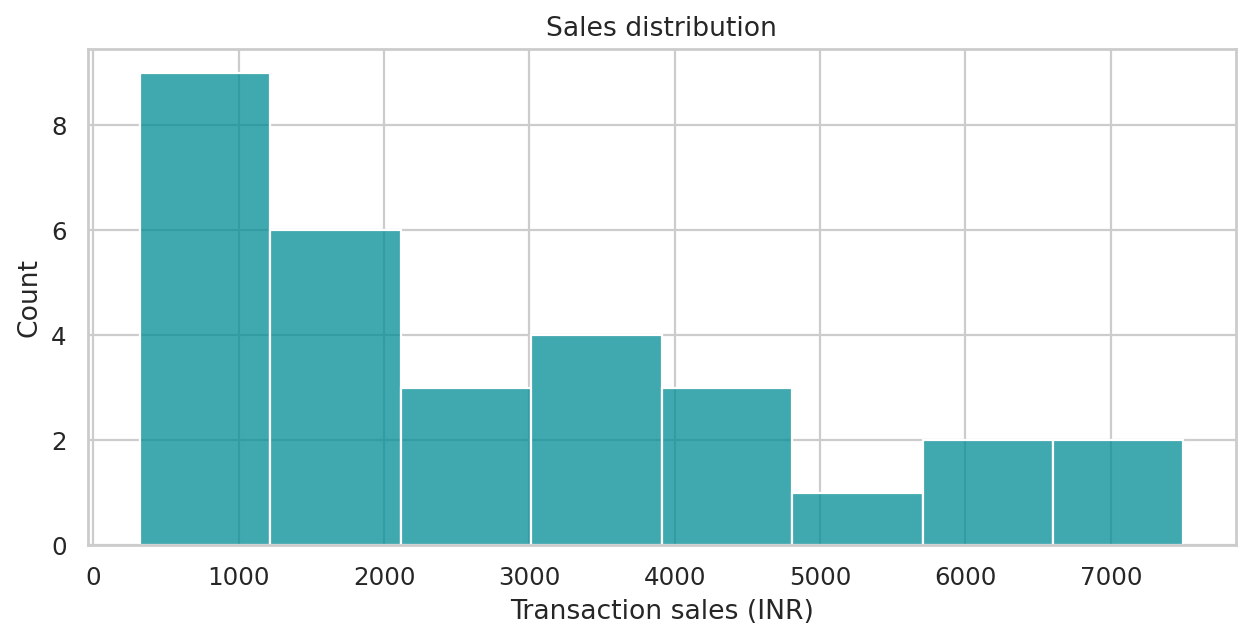

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(data=df, x="Sales", bins=8, ax=ax, color="#008C95"); ax.set_xlabel("Transaction sales (INR)")
ax.set_title('Sales distribution')
finish(fig, '06_distribution')

**What does this chart tell us?** Transactions range from INR 320 to INR 7,500; median is INR 2,075. Use this spread to assess order sizes.

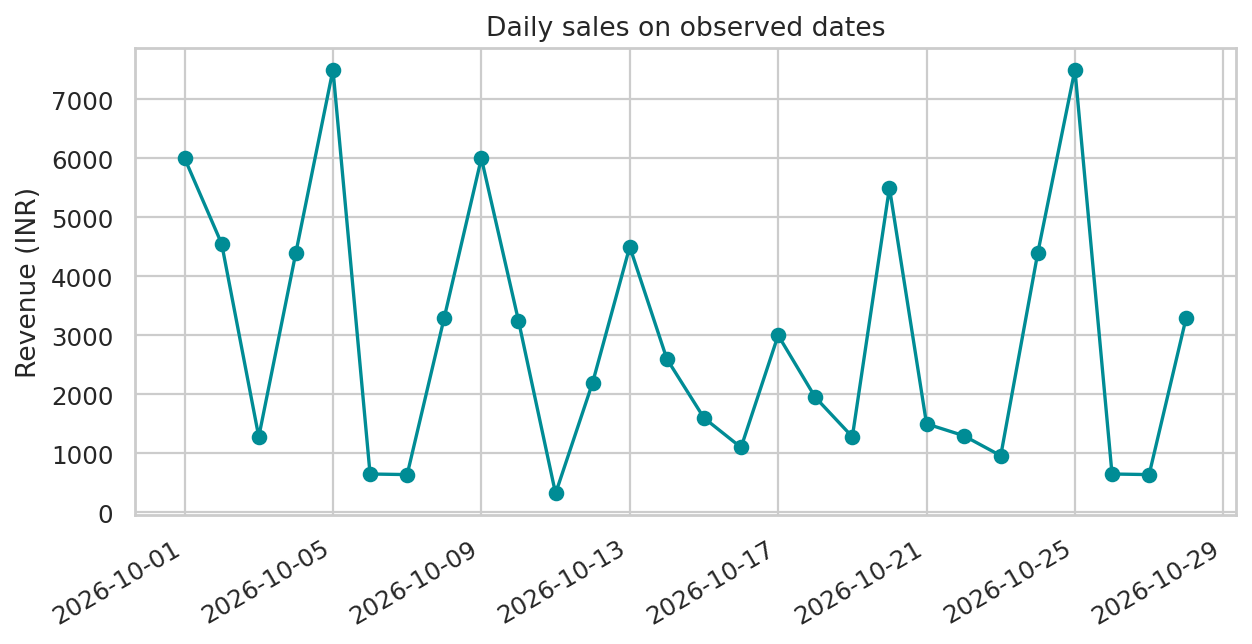

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
daily = df.groupby("Order_Date").Sales.sum(); ax.plot(daily.index, daily.values, marker="o", color="#008C95"); ax.set_ylabel("Revenue (INR)"); fig.autofmt_xdate()
ax.set_title('Daily sales on observed dates')
finish(fig, '07_daily')

**What does this chart tell us?** Highest observed daily revenue is INR 7,500 on 2026-10-05. Unobserved dates are not assumed to be zero.

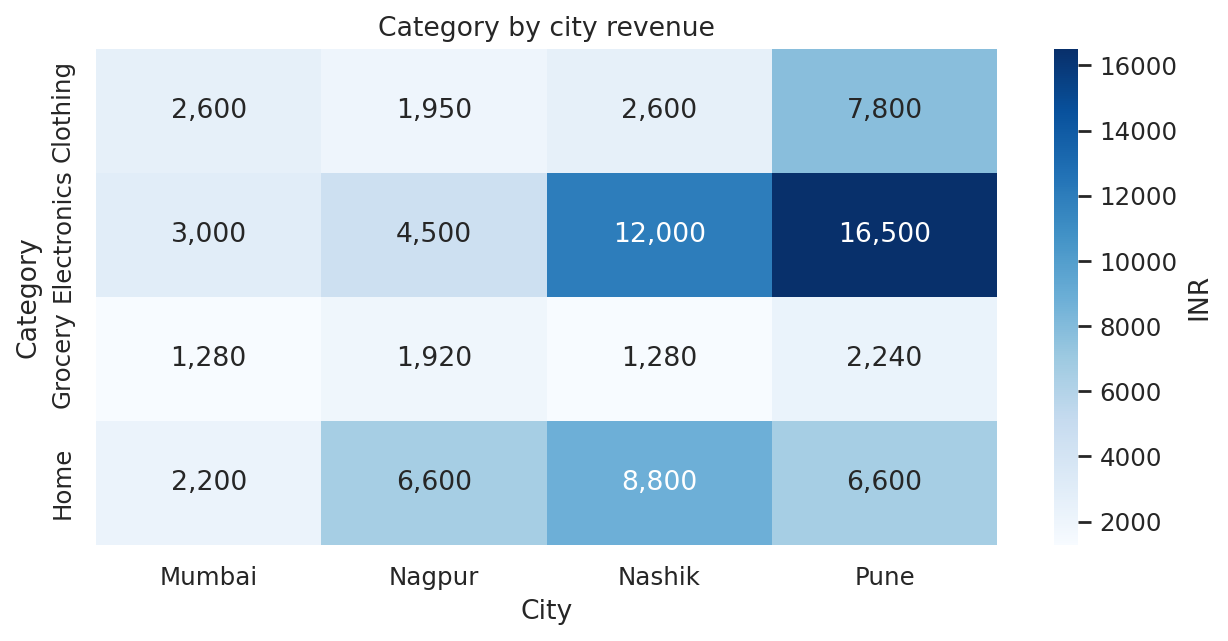

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="Blues", ax=ax, cbar_kws={"label":"INR"})
ax.set_title('Category by city revenue')
finish(fig, '08_pivot')

**What does this chart tell us?** The pivot heatmap compares category revenue across cities; zero denotes no recorded revenue for that combination in this dataset.

## Business recommendations
Prioritize availability of Headphones and investigate demand in Mumbai. Collect cost and profit data before making margin decisions. Collect additional months before forecasting. Validate city-to-region mapping and review product revenue alongside units and inventory.